Setup and loading the CSV files

In [2]:
# Colab: upload files into /content or change DATA_DIR to your directory.
# Optional: !pip -q install shap
import os, glob, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, classification_report
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.base import clone
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42
DATA_DIR=Path('/content') if Path('/content').exists() else Path('/mnt/data')
print('CSV files:', [p.name for p in DATA_DIR.glob('*.csv')])
def find_csv(pattern):
    matches=sorted(DATA_DIR.glob(pattern))
    return matches[-1] if matches else None
train_path=find_csv('dataset_B_training*.csv')
test_path=find_csv('dataset_B_testing*.csv')
example_path=find_csv('dataset_B_example_submission*.csv')
if train_path is None: raise FileNotFoundError('Upload dataset_B_training.csv')
train_df=pd.read_csv(train_path)
train_df.columns=train_df.columns.str.strip()
test_df=pd.read_csv(test_path) if test_path else None
if test_df is not None: test_df.columns=test_df.columns.str.strip()
example_df=pd.read_csv(example_path) if example_path else None
print('Training:',train_path,train_df.shape)
print('Matching test:',test_path, None if test_df is None else test_df.shape)
print('Example submission:',example_path)
TARGET='h1n1_vaccine'; ID='respondent_id'
assert TARGET in train_df.columns and ID in train_df.columns
X=train_df.drop(columns=[TARGET,ID]); y=train_df[TARGET].astype(int)
if test_df is not None:
    missing=set(X.columns)-set(test_df.columns)
    if missing: raise ValueError(f'Test file lacks training features: {sorted(missing)}')
    X_submission=test_df[X.columns].copy()
else:
    print('Upload the matching dataset_B_testing.csv before running Section 6.')


CSV files: ['dataset_A_testing.csv', 'dataset_B_training.csv']
Training: /content/dataset_B_training.csv (4756, 31)
Matching test: None None
Example submission: None
Upload the matching dataset_B_testing.csv before running Section 6.


Section 1 — Task-specific cost metric

In [3]:
# ILLUSTRATIVE ONLY — edit using the actual assignment cost table.
COST_TP=20.0    # offer dose to actual class 1
COST_FP=20.0    # offer dose to actual class 0
COST_FN=500.0   # no offer to actual class 1
COST_TN=0.0     # no offer to actual class 0
VACCINE_EFFECTIVENESS=0.60

def total_cost(y_true, y_pred, cost_tp=COST_TP, cost_fp=COST_FP,
               cost_fn=COST_FN, cost_tn=COST_TN):
    tn,fp,fn,tp=confusion_matrix(y_true,y_pred,labels=[0,1]).ravel()
    return tn*cost_tn+fp*cost_fp+fn*cost_fn+tp*cost_tp

def decision_threshold(cost_tp=COST_TP,cost_fp=COST_FP,cost_fn=COST_FN,cost_tn=COST_TN):
    # Compare expected offer cost with expected no-offer cost.
    denom=(cost_fp-cost_tn)+(cost_fn-cost_tp)
    if denom<=0: raise ValueError('Cost matrix does not yield this threshold rule')
    return (cost_fp-cost_tn)/denom

THRESHOLD=decision_threshold()
print('Illustrative probability threshold:',THRESHOLD)
print('Test cost:',total_cost([0,0,1,1],[0,1,0,1]))
print(pd.DataFrame([[COST_TN,COST_FP],[COST_FN,COST_TP]],
                   index=['Actual 0','Actual 1'],columns=['Predict 0','Predict 1']))


Illustrative probability threshold: 0.04
Test cost: 540.0
          Predict 0  Predict 1
Actual 0        0.0       20.0
Actual 1      500.0       20.0


Section 2 — Exploratory data analysis

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_concern                   4741 non-null   float64
 2   h1n1_knowledge                 4734 non-null   float64
 3   behavioral_antiviral_meds      4739 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4752 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4741 non-null   float64
 9   behavioral_touch_face          4736 non-null   float64
 10  doctor_recc_h1n1               4437 non-null   float64
 11  child_under_6_months           4622 non-null   float64
 12  health_worker                  4625 non-null   f

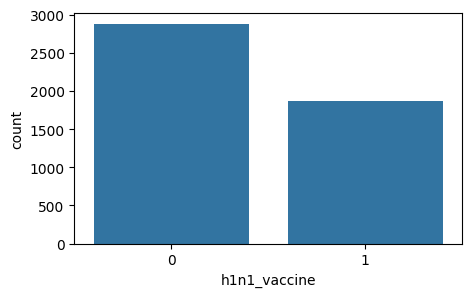

Missing percentages:
 employment_sector              49.71
health_insurance               40.48
income_poverty                 14.97
doctor_recc_h1n1                6.71
rent_or_own                     6.62
employment_status               4.94
marital_status                  4.75
education                       4.71
child_under_6_months            2.82
health_worker                   2.75
opinion_h1n1_vacc_effective     1.45
opinion_h1n1_risk               1.35
opinion_h1n1_sick_from_vacc     1.35
household_adults                0.71
household_children              0.71
behavioral_avoidance            0.57
h1n1_knowledge                  0.46
behavioral_touch_face           0.42
behavioral_antiviral_meds       0.36
h1n1_concern                    0.32
behavioral_outside_home         0.32
behavioral_large_gatherings     0.19
behavioral_wash_hands           0.17
behavioral_face_mask            0.08
dtype: float64


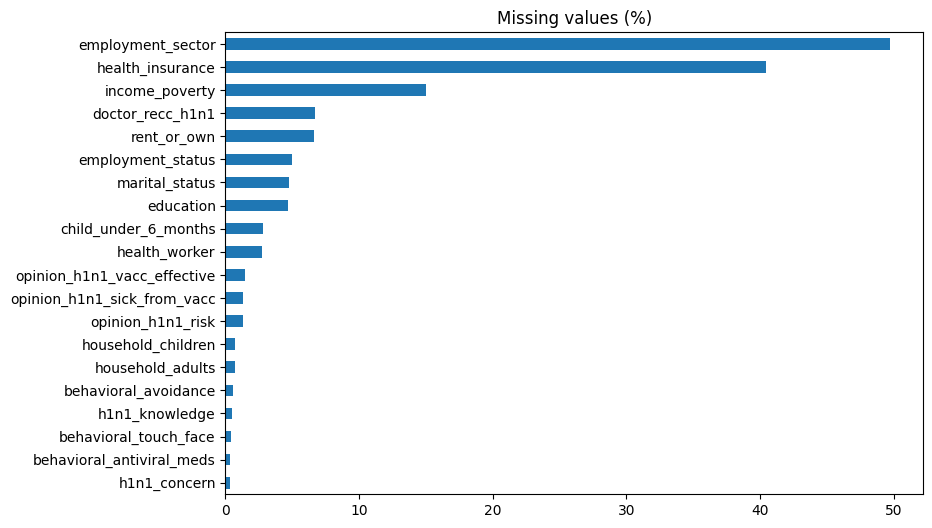


 age_group 
                 mean  count
age_group                  
18 - 34 Years  0.365    894
35 - 44 Years  0.396    659
45 - 54 Years  0.366    913
55 - 64 Years  0.419   1065
65+ Years      0.414   1225


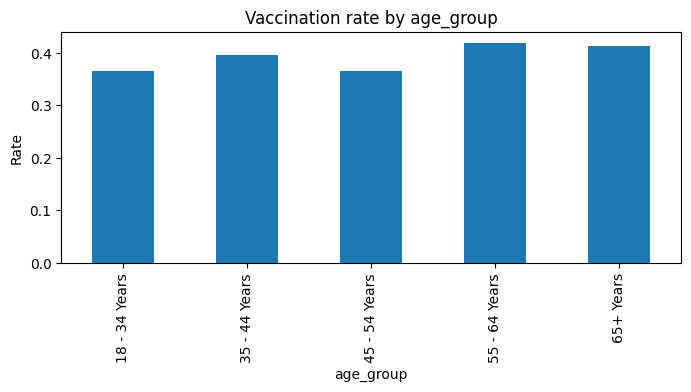


 doctor_recc_h1n1 
                    mean  count
doctor_recc_h1n1              
0.0               0.279   3149
1.0               0.727   1288
NaN               0.182    319


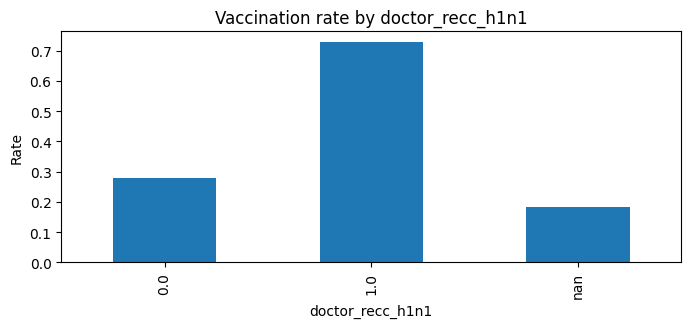


 health_worker 
                 mean  count
health_worker              
0.0            0.355   3972
1.0            0.643    653
NaN            0.344    131


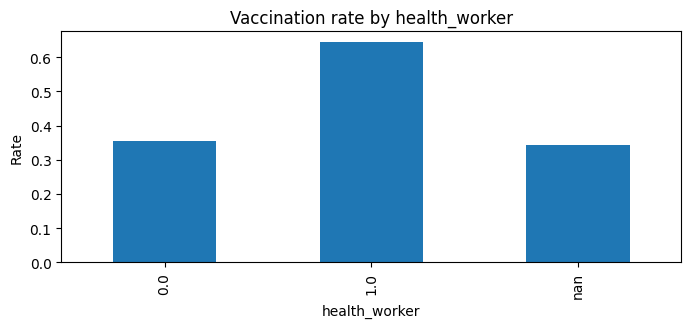


 opinion_h1n1_risk 
                     mean  count
opinion_h1n1_risk              
1.0                0.199   1274
2.0                0.324   1683
3.0                0.360    178
4.0                0.611   1171
5.0                0.705    386
NaN                0.391     64


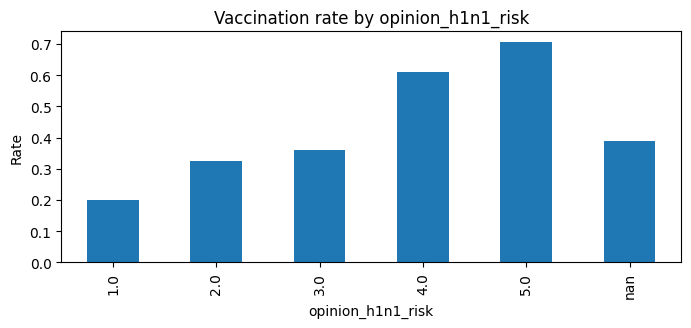

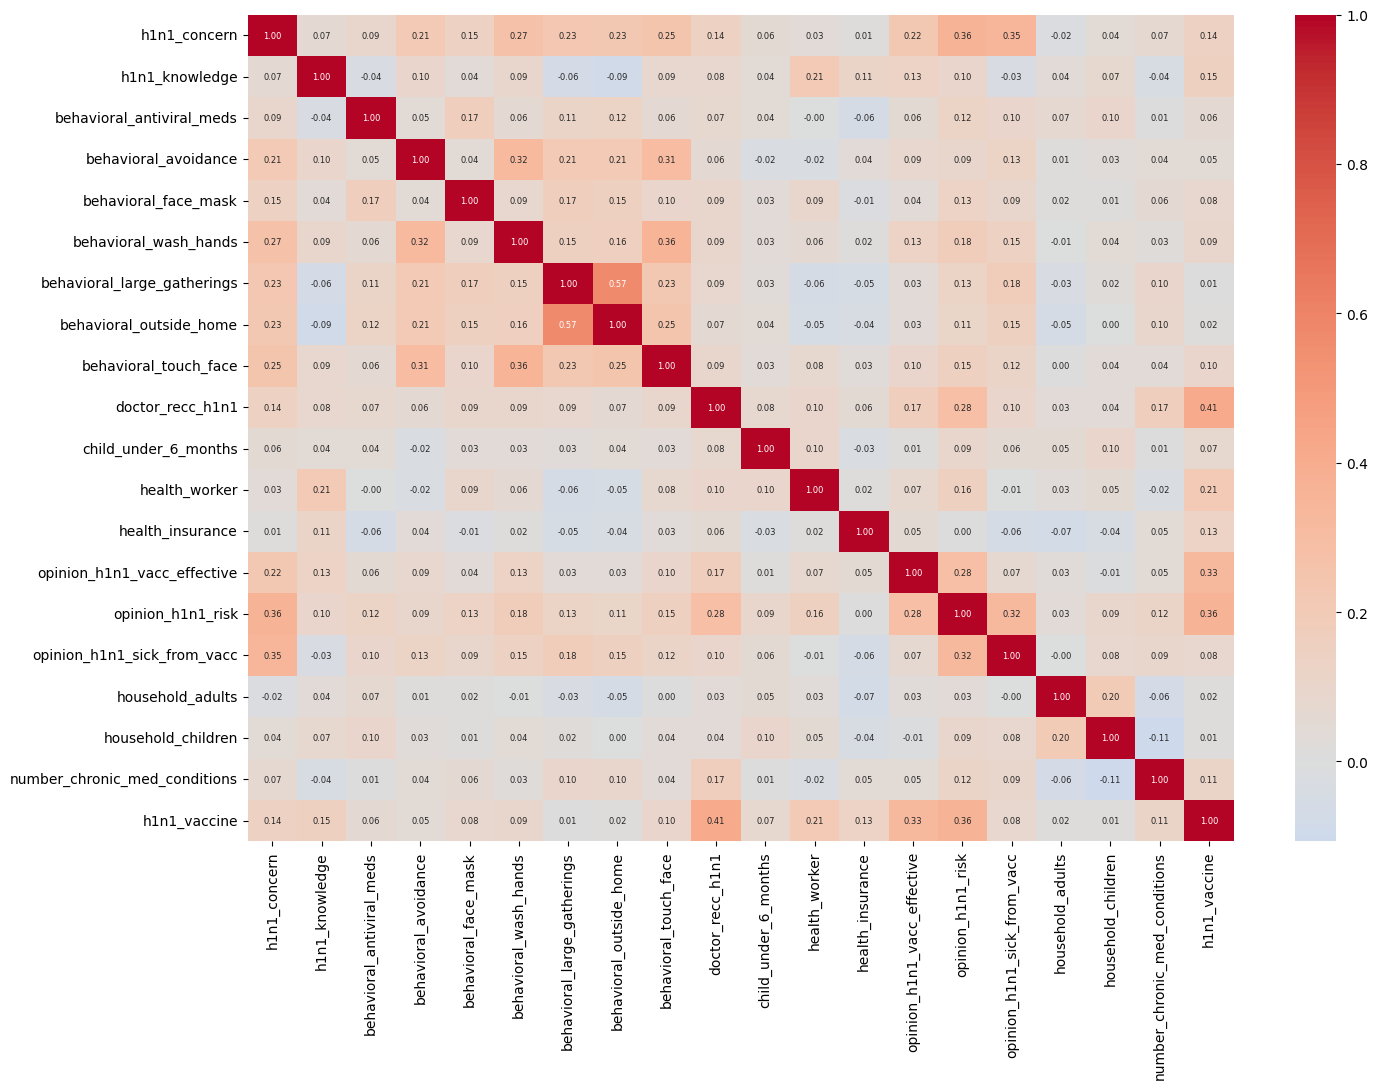

In [4]:
print(train_df.info())
print(train_df.describe(include='all').T)
print('Target balance:\n',y.value_counts(dropna=False))
print('Target proportions:\n',y.value_counts(normalize=True))
fig,ax=plt.subplots(figsize=(5,3));sns.countplot(data=train_df,x=TARGET,ax=ax);plt.show()
missing=train_df.isna().mean().mul(100).sort_values(ascending=False)
print('Missing percentages:\n',missing[missing>0].round(2))
missing.head(20).sort_values().plot.barh(figsize=(9,6),title='Missing values (%)');plt.show()
# Acceptance by feature (association, not causal effect)
for feature in ['age_group','doctor_recc_h1n1','health_worker','opinion_h1n1_risk']:
    if feature in train_df:
        print('\n',feature,'\n',train_df.groupby(feature,dropna=False)[TARGET].agg(['mean','count']).round(3))
        train_df.groupby(feature,dropna=False)[TARGET].mean().plot.bar(title=f'Vaccination rate by {feature}',figsize=(8,3));plt.ylabel('Rate');plt.show()
num=train_df.drop(columns=[ID]).select_dtypes(include=np.number)
plt.figure(figsize=(15,11));sns.heatmap(num.corr(),cmap='coolwarm',center=0,annot=True,fmt='.2f',annot_kws={'size':6});plt.tight_layout();plt.show()


Section 3 — Pre-processing: variants A and B

In [5]:
numeric_cols=X.select_dtypes(include=np.number).columns.tolist()
cat_cols=X.select_dtypes(exclude=np.number).columns.tolist()
def make_preprocessor(variant='B'):
    numeric_steps=[('impute',SimpleImputer(strategy='median'))]
    if variant=='B': numeric_steps.append(('scale',StandardScaler()))
    numeric=Pipeline(numeric_steps)
    categorical=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                          ('onehot',OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('num',numeric,numeric_cols),('cat',categorical,cat_cols)])
prep_A=make_preprocessor('A')  # median + one-hot
prep_B=make_preprocessor('B')  # median + scaling + one-hot
X_train,X_valid,y_train,y_valid=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
print('Train/validation:',X_train.shape,X_valid.shape)


Train/validation: (3804, 29) (952, 29)


Section 3.1 — Compare preprocessing variants on training folds

In [6]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
from sklearn.model_selection import cross_val_score
for variant in ['A','B']:
    pipe=Pipeline([('prep',make_preprocessor(variant)),('model',LogisticRegression(max_iter=1500))])
    auc=cross_val_score(pipe,X_train,y_train,cv=cv,scoring='roc_auc',n_jobs=-1)
    print(variant,'ROC AUC mean:',round(auc.mean(),4),'SD:',round(auc.std(),4))


A ROC AUC mean: 0.8217 SD: 0.0065
B ROC AUC mean: 0.8216 SD: 0.0065


Section 4 — Five models, GridSearchCV and cross-validation

In [7]:
models={
 'Logistic Regression':(LogisticRegression(max_iter=2000,random_state=SEED),{'model__C':[0.1,1,10]}),
 'Random Forest':(RandomForestClassifier(random_state=SEED,n_jobs=-1),{'model__n_estimators':[100,200],'model__max_depth':[None,12]}),
 'Decision Tree':(DecisionTreeClassifier(random_state=SEED),{'model__max_depth':[4,8,12],'model__min_samples_leaf':[5,20]}),
 'Gradient Boosting':(GradientBoostingClassifier(random_state=SEED),{'model__n_estimators':[100,150],'model__learning_rate':[0.05,0.1]}),
 'SVM':(SVC(probability=True,random_state=SEED),{'model__C':[0.5,2],'model__kernel':['linear','rbf']})
}
tuned={}; tuning_rows=[]
for name,(estimator,grid) in models.items():
    print('Tuning',name)
    pipe=Pipeline([('prep',make_preprocessor('B')),('model',estimator)])
    search=GridSearchCV(pipe,grid,scoring='roc_auc',cv=cv,n_jobs=-1,refit=True)
    search.fit(X_train,y_train)
    tuned[name]=search.best_estimator_
    tuning_rows.append({'Model':name,'CV ROC AUC':search.best_score_,'Best params':str(search.best_params_)})
tuning_table=pd.DataFrame(tuning_rows).sort_values('CV ROC AUC',ascending=False)
display(tuning_table)


Tuning Logistic Regression
Tuning Random Forest
Tuning Decision Tree
Tuning Gradient Boosting
Tuning SVM


,Model,CV ROC AUC,Best params
3,Gradient Boosting,0.830039,"{'model__learning_rate': 0.1, 'model__n_estima..."
1,Random Forest,0.828262,"{'model__max_depth': 12, 'model__n_estimators'..."
0,Logistic Regression,0.822173,{'model__C': 0.1}
4,SVM,0.821610,"{'model__C': 0.5, 'model__kernel': 'linear'}"
2,Decision Tree,0.799729,"{'model__max_depth': 4, 'model__min_samples_le..."


Section 4.1 — Optional probability calibration

In [9]:
from sklearn.calibration import CalibratedClassifierCV
RUN_CALIBRATION=False
calibrated={}
if RUN_CALIBRATION:
    for name,model in tuned.items():
        cal=CalibratedClassifierCV(estimator=clone(model),method='sigmoid',cv=3)
        cal.fit(X_train,y_train)
        calibrated[name]=cal
    print('Calibrated models:',list(calibrated))
else: print('Calibration skipped; set RUN_CALIBRATION=True to run.')


Calibration skipped; set RUN_CALIBRATION=True to run.


Section 5 — Cost-based model comparison, five-fold cost and baselines

Send nobody: 187500.0
Send everyone: 19040.0
Perfect classification: 7500.0


,Model,Validation cost,ROC AUC,Doses offered
0,SVM,18780.0,0.818699,939
1,Random Forest,19040.0,0.797782,952
2,Decision Tree,19040.0,0.773705,952
3,Gradient Boosting,19480.0,0.808562,949
4,Logistic Regression,19560.0,0.815117,928


Lowest validation cost: SVM


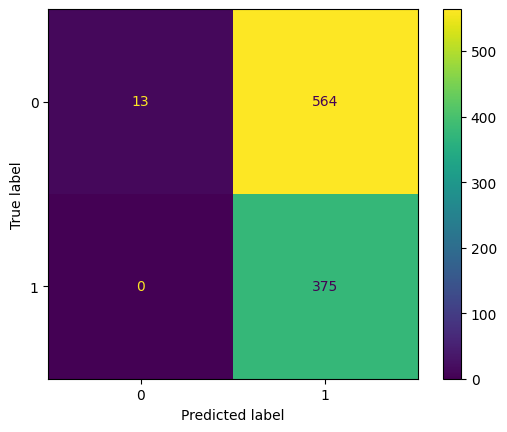

              precision    recall  f1-score   support

           0       1.00      0.02      0.04       577
           1       0.40      1.00      0.57       375

    accuracy                           0.41       952
   macro avg       0.70      0.51      0.31       952
weighted avg       0.76      0.41      0.25       952



In [10]:
active_models=calibrated if RUN_CALIBRATION else tuned
rows=[]; valid_predictions={}
for name,model in active_models.items():
    probs=model.predict_proba(X_valid)[:,1]
    pred=(probs>=THRESHOLD).astype(int)
    valid_predictions[name]=probs
    rows.append({'Model':name,'Validation cost':total_cost(y_valid,pred),
                 'ROC AUC':roc_auc_score(y_valid,probs),'Doses offered':int(pred.sum())})
comparison=pd.DataFrame(rows).sort_values('Validation cost').reset_index(drop=True)
print('Send nobody:',total_cost(y_valid,np.zeros(len(y_valid),dtype=int)))
print('Send everyone:',total_cost(y_valid,np.ones(len(y_valid),dtype=int)))
print('Perfect classification:',total_cost(y_valid,y_valid))
display(comparison)
BEST_NAME=comparison.iloc[0]['Model'];best_model=active_models[BEST_NAME]
print('Lowest validation cost:',BEST_NAME)
ConfusionMatrixDisplay.from_predictions(y_valid,(valid_predictions[BEST_NAME]>=THRESHOLD).astype(int));plt.show()
print(classification_report(y_valid,(valid_predictions[BEST_NAME]>=THRESHOLD).astype(int),zero_division=0))


In [11]:
# 5-fold out-of-fold predictions from training split, for each tuned configuration.
cv_rows=[]
for name,model in tuned.items():
    p_oof=cross_val_predict(clone(model),X_train,y_train,cv=cv,method='predict_proba',n_jobs=-1)[:,1]
    cv_rows.append({'Model':name,'5-fold OOF total cost':total_cost(y_train,(p_oof>=THRESHOLD).astype(int)),
                    '5-fold OOF AUC':roc_auc_score(y_train,p_oof)})
display(pd.DataFrame(cv_rows).sort_values('5-fold OOF total cost'))
# Note: best hyperparameters were selected using X_train, so this OOF score is not nested CV.


,Model,5-fold OOF total cost,5-fold OOF AUC
1,Random Forest,76080.0,0.827416
2,Decision Tree,76080.0,0.798741
3,Gradient Boosting,76340.0,0.829616
4,SVM,76420.0,0.820951
0,Logistic Regression,77580.0,0.821719


Section 5.1 — Cost vs number of doses offered

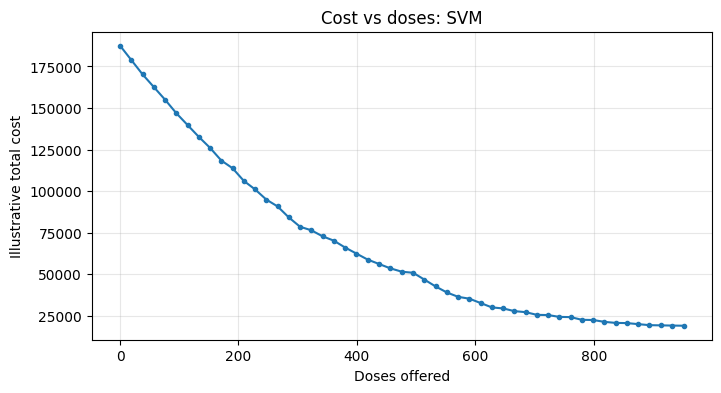

In [13]:
p=valid_predictions[BEST_NAME]
order=np.argsort(-p)
counts=np.unique(np.linspace(0,len(p),51,dtype=int))
curve=[]
for k in counts:
    offer=np.zeros(len(p),dtype=int);offer[order[:k]]=1
    curve.append(total_cost(y_valid,offer))
plt.figure(figsize=(8,4));plt.plot(counts,curve,marker='o',markersize=3)
plt.xlabel('Doses offered');plt.ylabel('Illustrative total cost');plt.title(f'Cost vs doses: {BEST_NAME}');plt.grid(alpha=.3);plt.show()


Section 5.2 — Sensitivity: vaccine effectiveness × risk multiplier

In [14]:
sens=[]
for effectiveness in [0.4,0.6,0.8]:
    for risk_multiplier in [1,2]:
        # Effective avoidable harm under assumed vaccine effectiveness.
        effective_fn=COST_FN*effectiveness*risk_multiplier
        threshold=decision_threshold(cost_fn=effective_fn)
        pred=(p>=threshold).astype(int)
        cost=total_cost(y_valid,pred,cost_fn=effective_fn)
        sens.append({'Effectiveness':effectiveness,'Risk multiplier':risk_multiplier,
                     'Threshold':threshold,'Total cost':cost,'Doses':int(pred.sum())})
display(pd.DataFrame(sens))


,Effectiveness,Risk multiplier,Threshold,Total cost,Doses
0,0.4,1,0.100000,18460.0,853
1,0.4,2,0.050000,19000.0,930
2,0.6,1,0.066667,19020.0,906
3,0.6,2,0.033333,18840.0,942
4,0.8,1,0.050000,19000.0,930
5,0.8,2,0.025000,18920.0,946


Section 6 — Top five models and five CSV submissions

In [21]:

print("Training columns:")
print(X.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

print("\nTraining shape:", X.shape)
print("Testing shape:", test_df.shape)


Training columns:
['h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'employment_sector', 'number_chronic_med_conditions']

Testing columns:
['respondent_id', 'flu_concern', 'flu_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_seasonal', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_seas_vacc_effective', 'opini

In [26]:

import pandas as pd

print("Training dataset features:", len(X.columns))
print("Testing dataset features:", len(X_submission.columns))

missing = sorted(set(X.columns) - set(X_submission.columns))
extra = sorted(set(X_submission.columns) - set(X.columns))

print("\nMissing features:")
print(missing)

print("\nExtra features:")
print(extra)

print("\nDataset compatibility:",
      "Compatible" if not missing and not extra
      else "Not compatible")


Training dataset features: 29
Testing dataset features: 29

Missing features:
['doctor_recc_h1n1', 'h1n1_concern', 'h1n1_knowledge', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'opinion_h1n1_vacc_effective']

Extra features:
['doctor_recc_seasonal', 'flu_concern', 'flu_knowledge', 'opinion_seas_risk', 'opinion_seas_sick_from_vacc', 'opinion_seas_vacc_effective']

Dataset compatibility: Not compatible


In [30]:

import pandas as pd
from pathlib import Path

for file in sorted(Path("/content").glob("*.csv")):
    df = pd.read_csv(file, nrows=3)
    print("\nFile:", file.name)
    print("Columns:", df.columns.tolist())



File: dataset_A_testing.csv
Columns: ['respondent_id', 'flu_concern', 'flu_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_seasonal', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_seas_vacc_effective', 'opinion_seas_risk', 'opinion_seas_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'employment_sector', 'number_chronic_med_conditions']

File: dataset_B_training.csv
Columns: ['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker',

In [31]:

from pathlib import Path

test_path = "/content/dataset_A_testing.csv"
train_path = "/content/dataset_A_training.csv"

print("Testing file exists:", Path(test_path).exists())
print("Training file exists:", Path(train_path).exists())


Testing file exists: True
Training file exists: False


In [35]:

import pandas as pd
from pathlib import Path

TEST_PATH = "/content/dataset_A_testing.csv"
EXAMPLE_PATH = "/content/dataset_A_example_submission.csv"

test_df = pd.read_csv(TEST_PATH)
example_df = pd.read_csv(EXAMPLE_PATH)

ID = "respondent_id"
TARGET = "seasonal_vaccine"

print("Testing shape:", test_df.shape)
print("Example shape:", example_df.shape)

assert list(example_df.columns) == [ID, TARGET]
assert len(test_df) == len(example_df)
assert test_df[ID].equals(example_df[ID])

print("Submission format verified!")
print(example_df.head())


Testing shape: (4749, 30)
Example shape: (4749, 2)
Submission format verified!
   respondent_id  seasonal_vaccine
0           4757               0.0
1           4758               0.0
2           4759               0.0
3           4760               0.0
4           4761               0.0


In [41]:
import pandas as pd

test_df = pd.read_csv("/content/dataset_A_testing.csv")

test_df.columns = test_df.columns.str.strip()

print("Testing shape:", test_df.shape)
print("Testing columns:", test_df.columns.tolist())

# Prepare testing features
X_submission = test_df.drop(
    columns=["respondent_id", "seasonal_vaccine"],
    errors="ignore"
)

print("X_submission shape:", X_submission.shape)

Testing shape: (4749, 30)
Testing columns: ['respondent_id', 'flu_concern', 'flu_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_seasonal', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_seas_vacc_effective', 'opinion_seas_risk', 'opinion_seas_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'employment_sector', 'number_chronic_med_conditions']
X_submission shape: (4749, 29)


In [49]:

# ==================================================
# DATASET B - 5 MACHINE LEARNING SUBMISSION FILES
# ==================================================

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import os
import shutil

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from google.colab import files

# ==================================================
# STEP 2: LOAD DATASETS
# ==================================================

train_df = pd.read_csv(
    "/content/dataset_B_training.csv"
)

test_df = pd.read_csv(
    "/content/dataset_A_testing.csv"
)

train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

# ==================================================
# STEP 3: PREPARE FEATURES
# ==================================================

TARGET = "h1n1_vaccine"
ID = "respondent_id"

if TARGET not in train_df.columns:
    raise ValueError("Target column missing in training data")

if ID not in train_df.columns or ID not in test_df.columns:
    raise ValueError("respondent_id column missing")

X = train_df.drop(
    columns=[ID, TARGET],
    errors="ignore"
)

y = train_df[TARGET]

X_test = test_df.drop(
    columns=[ID, TARGET],
    errors="ignore"
)

# Identify differences
missing_cols = sorted(set(X.columns) - set(X_test.columns))
extra_cols = sorted(set(X_test.columns) - set(X.columns))

print("\nMissing Testing Columns:", missing_cols)
print("Extra Testing Columns:", extra_cols)

# Use features available in both datasets
common_cols = X.columns.intersection(X_test.columns).tolist()

if not common_cols:
    raise ValueError("No matching prediction features found")

X = X[common_cols].copy()
X_test = X_test[common_cols].copy()

# Remove rows with missing target
valid_target = y.notna()
X = X.loc[valid_target].copy()
y = y.loc[valid_target].astype(int)

if set(y.unique()) != {0, 1}:
    raise ValueError("Expected binary target labels 0 and 1")

print("\nFinal Training Shape:", X.shape)
print("Final Testing Shape:", X_test.shape)

# ==================================================
# STEP 4: DATA PREPROCESSING
# ==================================================

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# ==================================================
# STEP 5: SPLIT DATA FOR EVALUATION
# ==================================================

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Rows:", len(X_train))
print("Validation Rows:", len(X_val))

# ==================================================
# STEP 6: DEFINE FIVE MODELS
# ==================================================

models = {
    "logistic_regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "decision_tree": DecisionTreeClassifier(
        max_depth=8,
        random_state=42
    ),

    "random_forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "svm": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),

    "gradient_boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

# ==================================================
# STEP 7: CREATE OUTPUT FOLDER
# ==================================================

output_folder = "/content/submissions"

os.makedirs(output_folder, exist_ok=True)

results = []

# ==================================================
# STEP 8: TRAIN AND EVALUATE MODELS
# ==================================================

for name, classifier in models.items():

    print("\n================================")
    print("Training:", name)
    print("================================")

    model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    # Train using training split
    model.fit(X_train, y_train)

    # Validation predictions
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(
        y_val, y_pred, zero_division=0
    )
    recall = recall_score(
        y_val, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_val, y_pred, zero_division=0
    )
    auc = roc_auc_score(y_val, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": auc
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("ROC AUC:", round(auc, 4))

    # ==================================================
    # STEP 9: RETRAIN ON COMPLETE TRAINING DATA
    # ==================================================

    model.fit(X, y)

    # Predict testing probabilities
    predictions = model.predict_proba(X_test)[:, 1]

    # ==================================================
    # STEP 10: GENERATE SUBMISSION CSV
    # ==================================================

    submission = pd.DataFrame({
        ID: test_df[ID].to_numpy(),
        TARGET: predictions
    })

    filename = f"{name}_submission.csv"
    filepath = os.path.join(output_folder, filename)

    submission.to_csv(filepath, index=False)

    print("CSV Created:", filename)
    print("Submission Rows:", len(submission))

# ==================================================
# STEP 11: PERFORMANCE COMPARISON
# ==================================================

performance_df = pd.DataFrame(results)

performance_df = performance_df.sort_values(
    by="ROC AUC",
    ascending=False
)

print("\nMODEL PERFORMANCE COMPARISON")
display(performance_df.round(4))

print(
    "\nBest Model:",
    performance_df.iloc[0]["Model"]
)

# Save performance results separately
performance_df.to_csv(
    "/content/model_performance.csv",
    index=False
)

# ==================================================
# STEP 12: CREATE ZIP WITH FIVE CSV FILES
# ==================================================

zip_path = shutil.make_archive(
    "/content/5_model_submissions",
    "zip",
    output_folder
)

print("\n================================")
print("SUCCESS!")
print("All 5 CSV files generated")
print("================================")

print("\nFiles Generated:")

for filename in sorted(os.listdir(output_folder)):
    print(filename)

# ==================================================
# STEP 13: DOWNLOAD FILES
# ==================================================

files.download(zip_path)

files.download(
    "/content/model_performance.csv"
)


Training Shape: (4756, 31)
Testing Shape: (4749, 30)

Missing Testing Columns: ['doctor_recc_h1n1', 'h1n1_concern', 'h1n1_knowledge', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'opinion_h1n1_vacc_effective']
Extra Testing Columns: ['doctor_recc_seasonal', 'flu_concern', 'flu_knowledge', 'opinion_seas_risk', 'opinion_seas_sick_from_vacc', 'opinion_seas_vacc_effective']

Final Training Shape: (4756, 23)
Final Testing Shape: (4749, 23)

Training Rows: 3804
Validation Rows: 952

Training: logistic_regression
Accuracy: 0.6649
Precision: 0.6321
Recall: 0.3573
F1 Score: 0.4566
ROC AUC: 0.6791
CSV Created: logistic_regression_submission.csv
Submission Rows: 4749

Training: decision_tree
Accuracy: 0.6092
Precision: 0.507
Recall: 0.2907
F1 Score: 0.3695
ROC AUC: 0.6037
CSV Created: decision_tree_submission.csv
Submission Rows: 4749

Training: random_forest
Accuracy: 0.6324
Precision: 0.5479
Recall: 0.3813
F1 Score: 0.4497
ROC AUC: 0.6069
CSV Created: random_forest_submission.csv
Submiss

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,logistic_regression,0.6649,0.6321,0.3573,0.4566,0.6791
4,gradient_boosting,0.6513,0.6059,0.3280,0.4256,0.6651
3,svm,0.6429,0.5989,0.2827,0.3841,0.6304
2,random_forest,0.6324,0.5479,0.3813,0.4497,0.6069
1,decision_tree,0.6092,0.5070,0.2907,0.3695,0.6037



Best Model: logistic_regression

SUCCESS!
All 5 CSV files generated

Files Generated:
decision_tree_submission.csv
gradient_boosting_submission.csv
logistic_regression_submission.csv
random_forest_submission.csv
svm_submission.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>